# ENSO-IOD ML/AI Enhancement Exploration

Approach: ML/AI techniques should progressively be used only in increasing complexity if lower-order models do not suffice. We begin with multi linear regression models with lags. If those do not hold, then we scale up to other methods. For interpretability, we will avoid neural networks completely.

**Data** NOAA Sea Surface Temperature [1], NOAA Dipole Mode Index (DMI) Monthly Time-series [2], Palay and Corn Volume of Production in Metric Tons and Area Harvested in Hectares (1987-2026) [3]

## Agricultural Productivity

Inputs: Using only relative Oceanic Nino Index and Dipole Mode Index, which have effective forecasting methodologies months in advance, can we predict crop yields? Need: We need the crop calendar per region. 
Outputs: Palay and Corn Volume of Production in Metric Tons and Area Harvested in Hectares. Note that the ground-truth data is in Quarter 1, Quarter 2, Quarter 3, and Quarter 4. 

### Alper's Methodology

\begin{equation}
\Delta \ln y_{r,t} = \alpha_r + \sum_{k=1}^{K} \beta_k \text{RONI}_{t-k} + \gamma'X_{r,t} + s_q + \tau t + \epsilon_{r,t}
\end{equation}

where:

- $\Delta \ln_{r,t}$ is the quarterly change in the logarithm of palay (rice) yield in region $r$.
- $\alpha_r$ is the fixed effect of region $r.$
- $\text{RONI}_{t-k}$ is the Relative Oceanic Nino Index $k$ quarters before quarter $t.$
- $\beta_k$ is the coefficient of the $k$-quarter lag. It is the percentage yield change associated with a one-degree RONI anomaly $k$ quarters earlier. The set of beta's across $k$ is the answer to the timing question.
- $K$ is the longest lag considered. It is set to four quarters on physical grounds because signals older than a year no longer affect a harvest.
- $X_{r,t}$ is the vector of acute-hazard controls for region $r$ in quarter $t.$ I.e. physical typhoon exposure, flood occurrence, and event markers for major earthquakes and volcanic eruptions.
- $\gamma$ is the list of coefficients belonging to those controls, one per control.
- $s_q$ is the quarterly seasonal dummies. 
- $\tau$ is the coefficient of a linear time trend. Its coefficients measures the slow, steady climb of yields due to better seed, fertiliser, and irrigation techniques.
- $\epsilon_{r,t}$ is the error term.

All of this is tied by:

$$
\beta_k = B \cdot w_k(\theta)
$$
and
$$\sum_{k=1}^{K} w_k(\theta) =1$$

## Labor Productivity

### Alper's Model

Heat does not only dry the field and empty the dams but it also slows people down. In this case, we use Wet Bulb Globe Temperature (WBGT) which is the appropriate measurement of felt temeprature, especially in a humid country. The regional WBGT is estimated by:

$$\Delta \text{WBGT}_t = \kappa \text{RONI}_t + u_t$$

where:
- $\Delta \text{WBGT}_t$ is the deviation of the periods regional Wet Bulb Globe Temperature from its seasonal norm, that is, how much hotter it feels than is usual for that time of year.
- $\kappa$ is the degrees of additional felt heat associated witha one-degree $\text{RONI}$ anomaly. 
- $u_t$ is the error term, carrying all the non-ENSO reasons a month can be hot. 

The felt heat is then converted into lost working capacity with the loss functions of the occupational health literature, applied with different severity to different sectors according to how much of their work happens outdoors:

$$A_{j,t} = A_j^0 \cdot [ 1 - g_j(\text{WGBT}_t) ]$$

### Van's Proposed Model

The connection from climate modes to WBGT to then labor productivity is a connection I agree with. A direct connect from climate modes to labor productivity would be more hasty. In addition, this model is flexible to shifting economic trends within a country. For example, the Philippines may become an increasingly service-based economy which would decrease the share of individuals working in outdoor environments. As mentioned in my previous ENSO and IOD paper, the IOD can have a dampening or strengthening effect on ENSO depending on the phase. While ENSO is the dominant driver of interannual temperature variability in Southeast Asia, I propose including the Indian Ocean Dipole as it can also have a serious impact on how hot the temperature is.

Both modes affect regional temperature with a delay, because the atmosphere responds to tropical Pacific and Indian Ocean SST changes through teleconnections and through changes in cloud cover, rainfall, and soil moisture that take weeks to months to develop. I therefore model WBGT as responding to the climate indices with a lag of ℓ months:

$$\Delta \text{WBGT}_{r,t} = \beta_0 + \beta_1 \text{RONI}_{t-\ell_1} + \beta_2 \text{DMI}_{t-\ell_2} + \beta_3 (\text{RONI}_{t-\ell_1} \cdot \text{DMI}_{t-\ell_2}) + \tau t + \epsilon_{r,t}$$

where:
- $\Delta \text{WBGT}_{r,t}$ is the WBGT anomaly for region r in month t,
- $\ell$ is the lag, in months, between a change in the climate indices and the WBGT response,
- $\beta_1$ represents the degrees of additional felt heat, $\ell_1$ months later, associated with a one-degree RONI anomaly,
- $\beta_2$ represents the degrees of additional felt heat, $\ell_2$ months later, associated with a one-degree DMI anomaly,
- $\beta_3$ captures how the IOD amplifies or dampens the ENSO effect,
- $\tau$ represents the coefficient of the time trend that is associated with climate change,
- $\epsilon_{r,t}$ represents all other residuals that can not be accounted for by RONI or DMI.

The lag $\ell$ is chosen from the data rather than assumed. I estimate the model for $\ell = 0, 1, \dots, 6.$

NOTE: Because RONI and DMI are both indices with temporal resolutions on a month-by-month basis, we have to then define WBGT on a month-by-month basis. I propose taking the average of the daily maximum WBGT within a given month. This prevents extreme days from skewing the regression. Note also that we are cherry picking the lag values and we could instead use the distributed lag like in agriculture.

**Testing how correlated RONI and DMI are** 

In [ ]:
import numpy as np
import pandas as pd

RONI_FILE = ""
DMI_FILE = ""

roni_ds = pd.read_csv(RONI_FILE)
dmi_ds = pd.read_csv(DMI_FILE)

print(roni_ds.tail())
print(dmi_ds.tail())

       month  rel_ssta
916  2026-04     -0.13
917  2026-05      0.52
918  2026-06      1.07
919  2026-07      1.33
920  2026-08      1.67
            Date     DMI
1879  2026-08-01 -9999.0
1880  2026-09-01 -9999.0
1881  2026-10-01 -9999.0
1882  2026-11-01 -9999.0
1883  2026-12-01 -9999.0


In [25]:
import time
from datetime import datetime

START_YEAR = 1950
END_YEAR = 2025

roni_ds['month'] = pd.to_datetime(roni_ds['month'], format = '%Y-%m')
dmi_ds['Date'] = pd.to_datetime(dmi_ds['Date'], format = '%Y-%m-%d')

roni_ds = roni_ds[roni_ds['month'].dt.year.between(START_YEAR, END_YEAR)]
dmi_ds = dmi_ds[dmi_ds['Date'].dt.year.between(START_YEAR, END_YEAR)]

roni_ds['ym'] = roni_ds['month'].dt.to_period('M')
dmi_ds['ym'] = dmi_ds['Date'].dt.to_period('M')
merged = roni_ds.merge(dmi_ds, on='ym')

In [ ]:
from statsmodels.tsa.stattools import ccf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from scipy import stats

# Merging the dataframe
df = merged[['month','rel_ssta','DMI']].copy()

# Headline Correlation
print(df[['rel_ssta', 'DMI']].corr(method = 'pearson'))
print(df[['rel_ssta', 'DMI']].corr(method = 'spearman'))

r,p = stats.pearsonr(df['rel_ssta'], df['DMI'])
print(f"Pearson correlation coefficient: {r}, p-value: {p}")

# 2. Lagged Correlations (does one lead the other?)
lags = range (-6,7)
lagged = {k: df['rel_ssta'].corr(df['DMI'].shift(k)) for k in lags}

# 3. Rolling correlation (is the relationship stable over time?)
roll = df['rel_ssta'].rolling(120).corr(df['DMI']) # 10-year rolling correlation

# 4. Variance Inflation Factor (VIF) to check for multicollinearity
X = df[['rel_ssta','DMI']].copy()
X['RONI_x_DMI'] = X['rel_ssta'] * X['DMI']
X = sm.add_constant(X)
vif = {c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != 'const'}

print(vif)

          rel_ssta       DMI
rel_ssta  1.000000  0.218799
DMI       0.218799  1.000000
          rel_ssta       DMI
rel_ssta  1.000000  0.179444
DMI       0.179444  1.000000
Pearson correlation coefficient: 0.21879856222231658, p-value: 2.3958612883710663e-11
{'rel_ssta': np.float64(1.0726108496329945), 'DMI': np.float64(1.1246164660537428), 'RONI_x_DMI': np.float64(1.0788384967772628)}


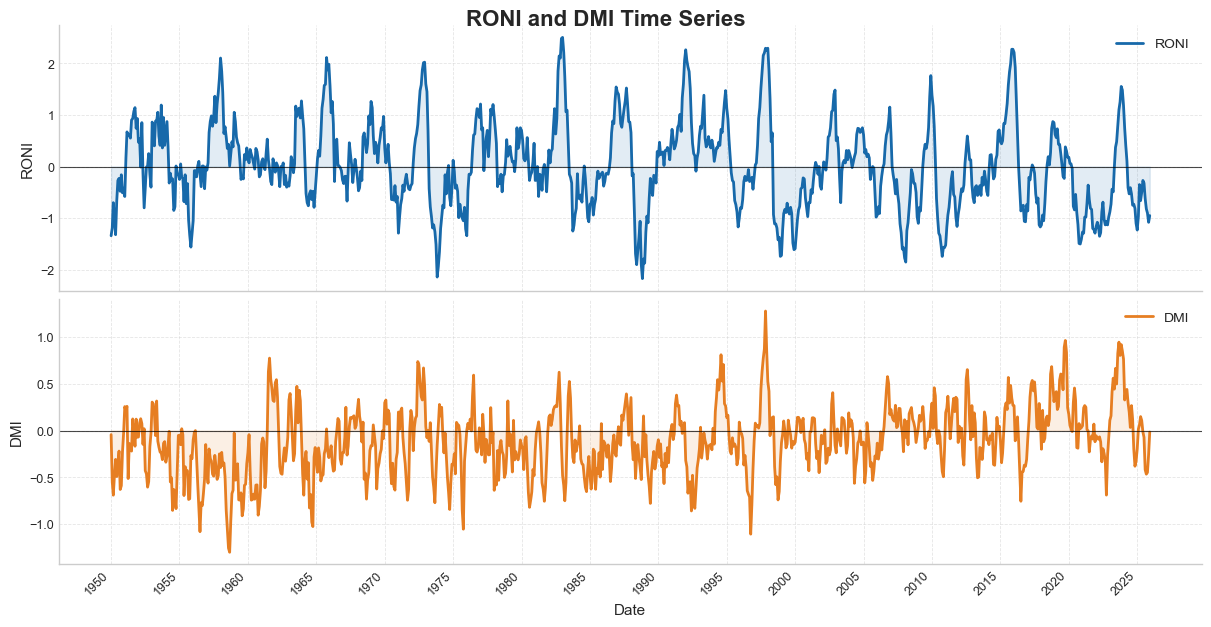

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Prepare data
df = df.copy()
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month")

plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True,
    constrained_layout=True
)

fig.suptitle(
    "RONI and DMI Time Series",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

# RONI
axes[0].plot(
    df["month"], df["rel_ssta"],
    color="#1769AA",
    linewidth=2,
    label="RONI"
)
axes[0].fill_between(
    df["month"], df["rel_ssta"], 0,
    color="#1769AA",
    alpha=0.12
)
axes[0].axhline(0, color="black", linewidth=0.8, alpha=0.7)
axes[0].set_ylabel("RONI", fontsize=11)
axes[0].legend(loc="upper right", frameon=False)

# DMI
axes[1].plot(
    df["month"], df["DMI"],
    color="#E67E22",
    linewidth=2,
    label="DMI"
)
axes[1].fill_between(
    df["month"], df["DMI"], 0,
    color="#E67E22",
    alpha=0.12
)
axes[1].axhline(0, color="black", linewidth=0.8, alpha=0.7)
axes[1].set_ylabel("DMI", fontsize=11)
axes[1].set_xlabel("Date", fontsize=11)
axes[1].legend(loc="upper right", frameon=False)

# Improve axes appearance
for ax in axes:
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)

# Show x-axis labels every five years
axes[1].xaxis.set_major_locator(mdates.YearLocator(5))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Optional: rotate labels slightly
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")

plt.show()

## Electrical Systems

### Alper's Model

On the supply side, part of the country's electricity comes from hydropower, and a dam is only as productive as the water behind it. When an El Nino cuts rainfall, reservoirs fall within a few months and generation follows. On the demand side, El Nino years are hotter, and hotter air means more air-conditioning and more fans, so consumption rises exactly when generation is falling. For the inflation outlook, it is an energy-cost story, and for the real economy, it is a supply-constraint story. The supply story is measured with a monthly equation, because the physics is fast here: a rainfall deficit reaches a reservoir within months, not seasons, so the lags are shorter than in agriculture and the data frequency can be higher.

$$\ln H_t = \alpha + \phi \ln R_t + \sum_{k}\delta_k \text{RONI}_{t-k} + s_m + \epsilon_t$$

where:

- $\ln H_t$ is the logarithm of the hydropower generation in month $t$
- $\ln R_t$ is the logarithm of reservoir inflows or storage levels at the major dams. 
- $\phi$ is the water-to-power elasticity. "Elasticity" means the percentage-to-percentage sensitivity.
- $\delta_k$ is the RONI lag coefficients of the channel.
- $s_m$ is the monthly seasonal dummies.
- $\epsilon_t$ is the error term.

Engineers summarise the need for cooling with cooling degree days (CDD). The idea is to pick a comfort threshold, count the degrees by which the daily mean exceeds the threshold, and add the amount of exceeding degrees over the month. The first link, from CDD to electricity consumption, is one of the most reliably estimated relationships in energy economics; every utility observes it in its own billing data. The second link, from the RONI to CDD is real but noisy, because a month's temperature is moved by many things besides ENSO. Splitting the chain into two steps keeps the strong link uncontaminated by the weak one. 

$$\ln D_t = \alpha + \eta \text{CDD}_t + \gamma' Z_t + \epsilon_t$$

and 

$$\text{CDD}_t  = c_0 + \kappa_D \text{RONI}_t + u_t$$

where

- $\ln D_t$ is the logarithm of the electricity consumption in month t, by grid
- $\text{CDD}_t$ is the cooling degree days of month $t,$ computed from daily mean temperatures as just described
- $\eta$ is the temperature-demand sesnitivity: the percentage rise in consumption per additional degree day (the strong, precisely estimated link)
- $Z_t$ is a list of controls such as economic activity and tariff changes, with $\gamma$ as their coefficients, so that consumption growth caused by the economy is not credited to the heat
- $\kappa_D$ is the effect of a one-degree RONI anomily on the month's CDD (the weak, noisy link)
- $c_0$ and $u_t$ is the intercept and the error term of the auxiliary temperature equation. 

### Van's Proposed Model

ENSO is the dominant driver of interannual rainfall variability in the Philippines, but it is not the only one. As mentioned in my previous ENSO and IOD paper, the Indian Ocean Dipole can dampen or strengthen the ENSO signal depending on its phase, so an El Nino that coincides with one IOD phase may cut inflows more than the same El Nino coinciding with the other. I therefore include the IOD, measured by the Dipole Mode Index (DMI), alongside RONI, together with an interaction term that lets the IOD state modify the ENSO effect. Both modes affect rainfall and inflows with a delay, because the atmosphere responds to tropical Pacific and Indian Ocean SST changes through teleconnections, and rainfall must then travel through the watershed into the reservoir. I model hydropower as responding to the climate indices with a lag of $\ell$ months:

$$\ln H_t = \alpha + \phi \ln R_t + \delta\,\text{RONI}_{t-\ell_1} + \gamma\,\text{DMI}_{t-\ell_2} + \lambda\,(\text{RONI}_{t-\ell_1} \cdot \text{DMI}_{t-\ell_2}) + s_m + \epsilon_t$$

where:

- $\ln H_t$ is the logarithm of the hydropower generation in month $t$
- $\ln R_t$ is the logarithm of reservoir inflows or storage levels at the major dams.
- $\phi$ is the water-to-power elasticity. "Elasticity" means the percentage-to-percentage sensitivity.
- $\ell$ is the lag, in months, between a change in the climate indices and the hydropower response.
- $\delta$ is the percentage change in generation, $\ell_1$ months later, associated with a one-degree RONI anomaly.
- $\gamma$ is the percentage change in generation, $\ell_2$ months later, associated with a one-degree DMI anomaly.
- $\lambda$ captures how the IOD amplifies or dampens the ENSO effect.
- $s_m$ is the monthly seasonal dummies.
- $\epsilon_t$ is the error term.

The lag $\ell$ is chosen from the data rather than assumed. I estimate the model for $\ell = 0, 1, \dots, 6$ and select the best value.

Engineers summarise the need for cooling with cooling degree days (CDD). The idea is to pick a comfort threshold, count the degrees by which the daily mean exceeds the threshold, and add the amount of exceeding degrees over the month. The first link, from CDD to electricity consumption, is one of the most reliably estimated relationships in energy economics; every utility observes it in its own billing data. The second link, from the climate modes to CDD, is real but noisy, because a month's temperature is moved by many things besides ENSO and the IOD. Splitting the chain into two steps keeps the strong link uncontaminated by the weak one.

$$\ln D_t = \alpha + \eta \text{CDD}_t + \gamma' Z_t + \epsilon_t$$

and

$$\text{CDD}_t = c_0 + \kappa_D \text{RONI}_{t-\ell_1} + \mu_D \text{DMI}_{t-\ell_2} + \lambda_D (\text{RONI}_{t-\ell_1} \cdot \text{DMI}_{t-\ell_2}) + \tau t + u_t$$

where

- $\ln D_t$ is the logarithm of the electricity consumption in month t, by grid
- $\text{CDD}_t$ is the cooling degree days of month $t,$ computed from daily mean temperatures as just described
- $\eta$ is the temperature-demand sensitivity: the percentage rise in consumption per additional degree day (the strong, precisely estimated link)
- $Z_t$ is a list of controls such as economic activity and tariff changes, with $\gamma$ as their coefficients, so that consumption growth caused by the economy is not credited to the heat
- $\ell$ is the lag, in months, between a change in the climate indices and the response of the month's CDD
- $\kappa_D$ is the effect of a one-degree RONI anomaly, $\ell_1$ months earlier, on the month's CDD (the weak, noisy link)
- $\mu_D$ is the effect of a one-degree DMI anomaly, $\ell_2$ months earlier, on the month's CDD
- $\lambda_D$ captures how the IOD amplifies or dampens the ENSO effect on CDD
- $\tau$ is the coefficient of the linear time trend, which captures the warming associated with climate change, so that it is not credited to ENSO or the IOD
- $c_0$ and $u_t$ is the intercept and the error term of the auxiliary temperature equation.

The lag $\ell$ is chosen from the data rather than assumed. I estimate the CDD equation for $\ell = 0, 1, \dots, 6$ and select the best value.